# E.3 Measure difference, then explain it

A large allele-frequency difference is easy to see. What does it tell us about population history?

We will calculate the same $F_{ST}$ summary for a Tibetan–Han SNP near *EPAS1* and for an *AMY2B* copy-number expansion in dogs and wolves. The calculation measures differentiation. Other evidence is needed to distinguish drift, selection, introgression, and timing.


## Model outline and expected result

For two equally weighted populations with frequencies $p_1$ and $p_2$, let

$$
\bar p=\frac{p_1+p_2}{2},\qquad
H_T=2\bar p(1-\bar p),\qquad
H_S=\frac{2p_1(1-p_1)+2p_2(1-p_2)}{2}.
$$

Then $F_{ST}=(H_T-H_S)/H_T$. We expect both loci to have large values. We do **not** expect those values to identify the same history.

Yi et al. reported frequencies 0.87 in Tibetans and 0.09 in Han Chinese for the strongest differentiated *EPAS1* SNP. Arendt et al. found more than two *AMY2B* copies in 354 of 392 dogs and 1 of 51 wolves. For the second calculation, copy number is deliberately reduced to an expansion indicator.


In [1]:
library(hpgR)

frequency <- rbind(
  EPAS1_SNP = c(population_1 = 0.87, population_2 = 0.09),
  AMY2B_expansion = c(population_1 = 354 / 392, population_2 = 1 / 51)
)

result <- t(apply(frequency, 1, frequencyDifferentiation))
round(result, 3)


,p_bar,H_T,H_S,F_ST
EPAS1_SNP,0.480,0.499,0.195,0.609
AMY2B_expansion,0.461,0.497,0.107,0.785


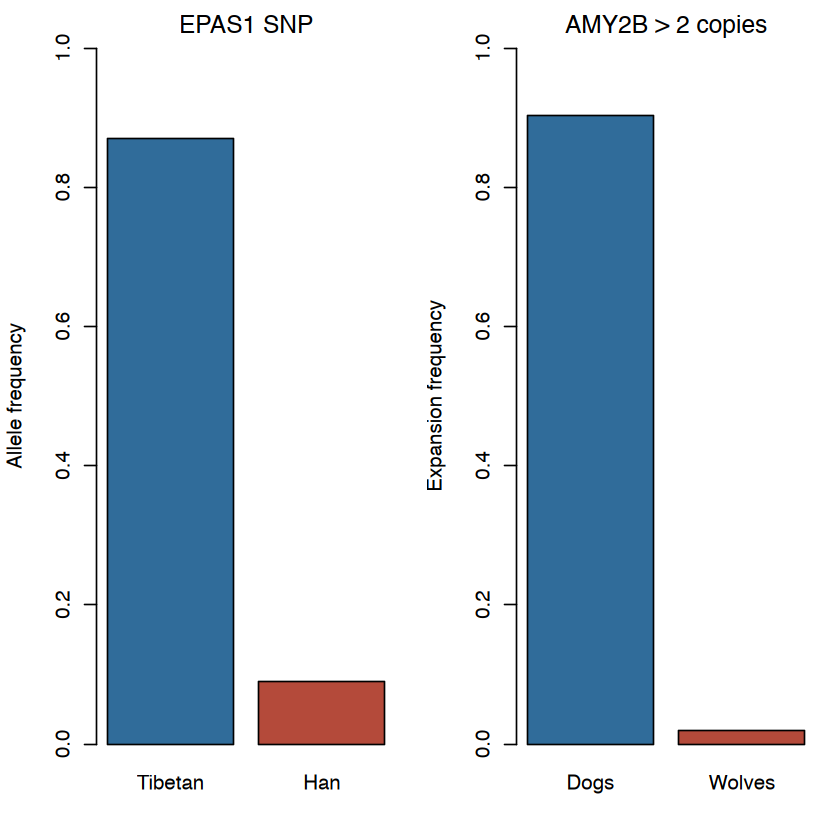

In [2]:
stopifnot(abs(result['EPAS1_SNP', 'F_ST'] - 0.609375) < 1e-10)
stopifnot(abs(result['AMY2B_expansion', 'F_ST'] - 0.7851853) < 1e-6)

old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1))
barplot(frequency['EPAS1_SNP', ], col = c('#306C9A', '#B44A3A'),
        ylim = c(0, 1), names.arg = c('Tibetan', 'Han'),
        ylab = 'Allele frequency', main = 'EPAS1 SNP')
barplot(frequency['AMY2B_expansion', ], col = c('#306C9A', '#B44A3A'),
        ylim = c(0, 1), names.arg = c('Dogs', 'Wolves'),
        ylab = 'Expansion frequency', main = 'AMY2B > 2 copies')
par(old_par)


Both values are large. That is the result the calculation can establish.

The *EPAS1* result becomes a history only after a local genealogy links the common Tibetan haplotype to Denisovan-related DNA and a high-altitude phenotype. The *AMY2B* result becomes a history only after ancient genomes and geographic samples constrain when and where copy number expanded. The binary *AMY2B* coding also hides differences among 3, 10, or 20 copies.

## What to remember

$F_{ST}$ measures differentiation relative to within-population variation. A large value is a question for population history, not its answer.

**Sources.** Yi et al. (2010), *Science*, doi:10.1126/science.1189406; Huerta-Sánchez et al. (2014), *Nature*, doi:10.1038/nature13408; Arendt et al. (2016), *Heredity*, doi:10.1038/hdy.2016.48. The calculations use the lecture's equal-weight heterozygosity definition, not the papers' genome-wide estimators.
